# Automatic Number Plate Recognition (ANPR) — Detect and Read Vehicle Number Plates

**Unit:** AI in Operations · Day 1, Session III lab task (slide 69): *"Build a Python script that detects and reads vehicle number plates from an image."*

This notebook builds a complete, evaluated ANPR system in **two stages**, the standard design used in production ANPR:

| Stage | Job | Model | Why this choice |
|---|---|---|---|
| 1. Detect | Find every plate in the photo (a box) | **YOLO11n**, fine-tuned here on 6,176 labelled photos | Small, fast CNN detector; transfer learning from COCO means it learns plates quickly |
| 2. Read | Turn each plate crop into text | **fast-plate-ocr** (`cct-s-v2-global-model`) | Recogniser trained only on licence plates from 65+ regions (Vietnam included); reads one- and two-line plates in ~20 ms |

```
photo ──► YOLO detector ──► plate boxes ──► crop + pad ──► plate OCR ──► "51F73420" + confidence ──► gate log / review queue
```

**Link to the lecture:** both stages are convolutional networks, the same building blocks as the MNIST CNN demo (Conv → Pool → Dense → Softmax). The detector predicts *where*; the OCR model predicts a character class at every position, just as the MNIST model predicted one digit.

**Dataset:** [Vehicle Registration Plates (Roboflow / Augmented Startups, CC BY 4.0)](https://huggingface.co/datasets/keremberke/license-plate-object-detection), 8,823 photos with hand-drawn plate boxes. Most images come from a **Vietnamese parking-garage barrier camera** (cars and motorbikes), exactly the "number plate detection in parking lot" scenario on the slide, plus international street photos from Open Images.

**How to run:** in Google Colab choose *Runtime → Change runtime type → T4 GPU*, then *Runtime → Run all* (about 35–45 min, mostly training). It also runs on a laptop CPU with fewer epochs.

> **About the saved outputs below.** Every cell was executed end to end on a laptop CPU as a *verification run* (`ANPR_FAST_DEV_RUN=1`: 1 training epoch on 5% of the images), to prove the whole pipeline runs without errors. The **detector numbers in this saved copy are therefore deliberately weak and NOT the real result.** The OCR accuracy figures do not depend on training and are representative. Open the notebook in Google Colab with a T4 GPU and choose *Runtime → Run all* to train the full model (30 epochs on all 6,176 images, ~35–45 min) and get the real detector and end-to-end scores.

## 1. Setup

In [1]:
import os, sys, subprocess, importlib.util

IN_COLAB = "google.colab" in sys.modules
# import name -> pip requirement (the two model libraries are pinned to the tested versions)
REQUIREMENTS = {"ultralytics": "ultralytics==8.4.209", "fast_plate_ocr": "fast-plate-ocr[onnx]==1.1.0",
                "pandas": "pandas", "matplotlib": "matplotlib"}
to_install = [req for mod, req in REQUIREMENTS.items()
              if importlib.util.find_spec(mod) is None or (IN_COLAB and "==" in req)]
if to_install:
    print("Installing:", to_install)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *to_install], check=True)
print("Running in Colab:", IN_COLAB)

Running in Colab: False


In [2]:
import json, re, shutil, random, zipfile, urllib.request, collections, math, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import torch
import ultralytics
from ultralytics import YOLO
from fast_plate_ocr import LicensePlateRecognizer

warnings.filterwarnings("ignore", category=UserWarning)
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

# Hardware: CUDA GPU (Colab) if present, else CPU. ANPR_DEVICE can override (e.g. "mps" on Apple Silicon).
DEVICE = os.environ.get("ANPR_DEVICE") or (0 if torch.cuda.is_available() else "cpu")
ON_GPU = DEVICE not in ("cpu",)

# FAST_DEV_RUN = quick smoke test (tiny training) used to verify every cell runs. Leave it off for real results.
FAST_DEV_RUN = os.environ.get("ANPR_FAST_DEV_RUN", "0") == "1"
EPOCHS         = 1 if FAST_DEV_RUN else (30 if ON_GPU else 5)
TRAIN_FRACTION = 0.05 if FAST_DEV_RUN else 1.0
IMG_SIZE       = 640
BATCH          = 32 if ON_GPU else 16
WORKERS        = 2 if ON_GPU else 0

WORK = Path("anpr_work")
DATA_RAW, YOLO_DIR = WORK / "raw", WORK / "yolo"
WORK.mkdir(exist_ok=True)

print(f"Python {sys.version.split()[0]} | torch {torch.__version__} | ultralytics {ultralytics.__version__} | OpenCV {cv2.__version__}")
print(f"Device: {DEVICE} | epochs: {EPOCHS} | train fraction: {TRAIN_FRACTION} | FAST_DEV_RUN: {FAST_DEV_RUN}")

Python 3.12.16 | torch 2.15.0 | ultralytics 8.4.209 | OpenCV 5.0.0
Device: cpu | epochs: 1 | train fraction: 0.05 | FAST_DEV_RUN: True


## 2. Download the dataset
Three zip files (train / valid / test, ~230 MB total) in COCO format. The cell skips the download if the data is already there.

In [3]:
HF_BASE = "https://huggingface.co/datasets/keremberke/license-plate-object-detection/resolve/main/data"
SPLITS = ["train", "valid", "test"]

for split in SPLITS:
    if (DATA_RAW / split / "_annotations.coco.json").exists():
        print(f"{split}: already downloaded"); continue
    (DATA_RAW / split).mkdir(parents=True, exist_ok=True)
    zip_path = DATA_RAW / f"{split}.zip"
    print(f"{split}: downloading ...")
    urllib.request.urlretrieve(f"{HF_BASE}/{split}.zip", zip_path)
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(DATA_RAW / split)
    zip_path.unlink()
    print(f"{split}: done")

train: already downloaded
valid: already downloaded
test: already downloaded


## 3. Understand the data before training
An expert checks three things first: **what the images are**, **how big the plates are**, and **whether the test set is truly independent of training**.

In [4]:
def source_of(stem):
    if re.fullmatch(r"[0-9a-f]{16}_jpg", stem):            return "Open Images (international)"
    if stem.startswith("CarLongPlateGen"):                 return "Parking cars (Gen set)"
    if stem.startswith("CarLongPlate"):                    return "Parking cars"
    if stem.startswith("xemayBigPlate"):                   return "Motorbikes (close-up)"
    if stem.startswith("xemay"):                           return "Parking motorbikes"
    if re.search(r"quandoi|ngoaigiao", stem):              return "Military / diplomatic (VN)"
    if stem.startswith("Cars"):                            return "Cars (India and other)"
    return "Other"

def family_of(stem):
    # "rotatequandoi56", "cropquandoi56" ... are edited copies of the photo "quandoi56"
    m = re.fullmatch(r"(?:rotate|brightness|crop|boder)?(quandoi|ngoaigiao)(\d+)_jpg", stem)
    return f"{m.group(1)}{m.group(2)}" if m else None

rows = []
for split in SPLITS:
    coco = json.loads((DATA_RAW / split / "_annotations.coco.json").read_text())
    boxes = collections.defaultdict(list)
    for a in coco["annotations"]:
        boxes[a["image_id"]].append(a["bbox"])          # COCO box = [x, y, w, h] in pixels
    for im in coco["images"]:
        stem = im["file_name"].split(".rf.")[0]           # Roboflow appends ".rf.<hash>"
        rows.append(dict(split=split, file=im["file_name"], stem=stem, width=im["width"], height=im["height"],
                         boxes=boxes[im["id"]], n_plates=len(boxes[im["id"]]),
                         source=source_of(stem), family=family_of(stem)))
df = pd.DataFrame(rows)

print(f"{len(df):,} images, {df.n_plates.sum():,} plates, images without a plate: {(df.n_plates == 0).sum()}")
display(pd.crosstab(df.source, df.split, margins=True))

8,823 images, 9,155 plates, images without a plate: 0


split,test,train,valid,All
source,,,,
Cars (India and other),29,206,64,299
Military / diplomatic (VN),51,458,106,615
Motorbikes (close-up),24,167,53,244
Open Images (international),28,193,50,271
Parking cars,85,712,203,1000
Parking cars (Gen set),405,2724,775,3904
Parking motorbikes,260,1716,514,2490
All,882,6176,1765,8823


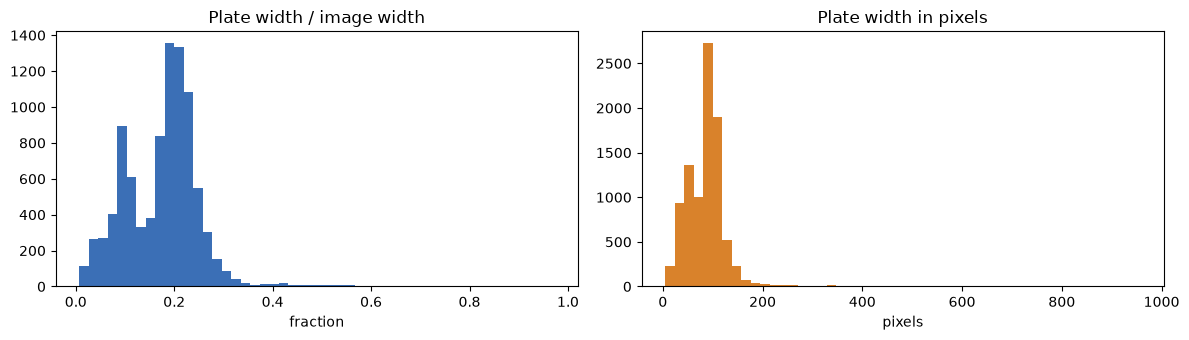

Median plate width: 90px | plates narrower than 40px: 8.8%


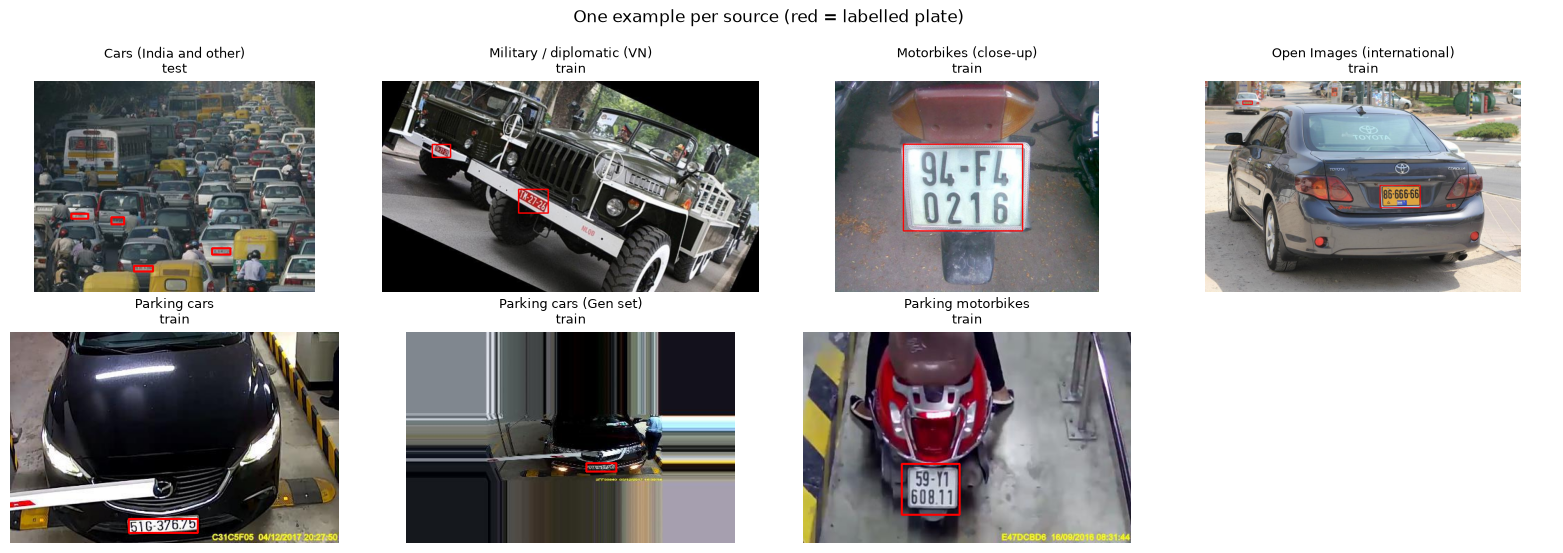

In [5]:
# Plate size relative to the image: small plates are the hard cases for both detection and reading
rel_w = [b[2] / r.width for r in df.itertuples() for b in r.boxes]
plate_px = [b[2] for r in df.itertuples() for b in r.boxes]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].hist(rel_w, bins=50, color="#3b6fb6"); ax[0].set_title("Plate width / image width"); ax[0].set_xlabel("fraction")
ax[1].hist(plate_px, bins=50, color="#d9822b"); ax[1].set_title("Plate width in pixels"); ax[1].set_xlabel("pixels")
plt.tight_layout(); plt.show()
print(f"Median plate width: {np.median(plate_px):.0f}px | plates narrower than 40px: {np.mean(np.array(plate_px) < 40):.1%}")

def show_grid(sample, ncols=4, title=None):
    nrows = math.ceil(len(sample) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 2.8 * nrows))
    for ax, r in zip(np.ravel(axes), sample.itertuples()):
        img = cv2.imread(str(DATA_RAW / r.split / r.file))
        for x, y, w, h in r.boxes:
            cv2.rectangle(img, (int(x), int(y)), (int(x + w), int(y + h)), (0, 0, 255), 2)
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax.set_title(f"{r.source}\n{r.split}", fontsize=9)
    for ax in np.ravel(axes): ax.axis("off")
    if title: fig.suptitle(title)
    plt.tight_layout(); plt.show()

show_grid(pd.concat([g.sample(1, random_state=SEED) for _, g in df.groupby("source")]).head(8),
          title="One example per source (red = labelled plate)")

### 3.1 Leakage audit: is the test set independent?
Two problems were found while auditing this dataset:

1. **Edited copies across splits.** Military and diplomatic photos appear several times (`quandoi56`, `rotatequandoi56`, `cropquandoi56` ...), and copies of the same photo sit in *both* train and test. A model has already "seen" those test images.
2. **Repeat vehicles.** The parking camera photographs the same cars on different days, and the "Gen" set holds re-scaled copies of some frames, so a few vehicles appear in more than one split.

Fix used here: we keep the official splits (so results are comparable), but we also report every test metric on a **clean test set** that removes all test images whose photo family appears in training. Problem 2 cannot be removed exactly without plate text for every image; it affects only a small share (about 1% of test plates have a near-identical training plate), so it is reported as a known limitation.

,images that are copies of a training photo,images
split,,
test,51,882
valid,106,1765


Clean test set: 831 of 882 test images kept


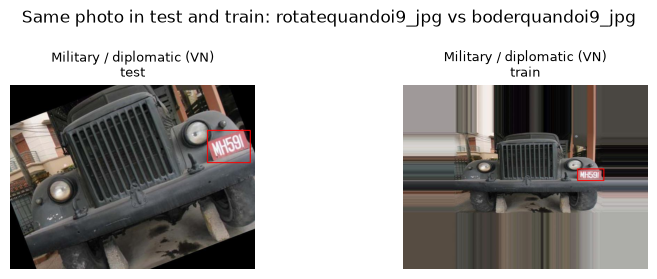

In [6]:
train_families = set(df.loc[df.split == "train", "family"].dropna())
df["leaks_from_train"] = (df.split != "train") & df.family.isin(train_families)
summary = df[df.split != "train"].groupby("split").leaks_from_train.agg(["sum", "count"])
summary.columns = ["images that are copies of a training photo", "images"]
display(summary)

test_clean = df[(df.split == "test") & ~df.leaks_from_train]
print(f"Clean test set: {len(test_clean)} of {(df.split == 'test').sum()} test images kept")

# Show one leaked pair: a test image next to its training copy
leak = df[(df.split == "test") & df.leaks_from_train].iloc[0]
twin = df[(df.split == "train") & (df.family == leak.family)].iloc[0]
show_grid(pd.DataFrame([leak, twin]), ncols=2, title=f"Same photo in test and train: {leak.stem} vs {twin.stem}")

## 4. Convert labels to YOLO format
YOLO wants one text file per image with `class cx cy w h`, all **normalised to 0–1**. Boxes are clipped to the image so no label points outside it.

In [7]:
def to_yolo_lines(r):
    lines = []
    for x, y, w, h in r.boxes:
        x0, y0 = max(0.0, x), max(0.0, y)
        x1, y1 = min(float(r.width), x + w), min(float(r.height), y + h)
        if x1 - x0 < 1 or y1 - y0 < 1:
            continue
        lines.append(f"0 {(x0 + x1) / 2 / r.width:.6f} {(y0 + y1) / 2 / r.height:.6f} "
                     f"{(x1 - x0) / r.width:.6f} {(y1 - y0) / r.height:.6f}")
    return lines

lists = collections.defaultdict(list)
for r in df.itertuples():
    img_dir, lbl_dir = YOLO_DIR / "images" / r.split, YOLO_DIR / "labels" / r.split
    img_dir.mkdir(parents=True, exist_ok=True); lbl_dir.mkdir(parents=True, exist_ok=True)
    dst = img_dir / r.file
    if not dst.exists():
        shutil.copy2(DATA_RAW / r.split / r.file, dst)
    (lbl_dir / f"{Path(r.file).stem}.txt").write_text("\n".join(to_yolo_lines(r)) + "\n")
    lists[r.split].append(str(dst.resolve()))
    if r.split == "test" and not r.leaks_from_train:
        lists["test_clean"].append(str(dst.resolve()))

if FAST_DEV_RUN:  # smaller validation set so the smoke test finishes quickly
    lists["valid"] = random.Random(SEED).sample(lists["valid"], 60)
for name, paths in lists.items():
    (YOLO_DIR / f"{name}.txt").write_text("\n".join(paths) + "\n")

def write_yaml(path, test_list):
    path.write_text(f"path: {YOLO_DIR.resolve()}\ntrain: train.txt\nval: valid.txt\ntest: {test_list}\n"
                    "names:\n  0: license_plate\n")
    return path

DATA_YAML  = write_yaml(YOLO_DIR / "plates.yaml", "test.txt")
CLEAN_YAML = write_yaml(YOLO_DIR / "plates_clean.yaml", "test_clean.txt")
print({k: len(v) for k, v in lists.items()})
print(open(DATA_YAML).read())

{'train': 6176, 'valid': 60, 'test': 882, 'test_clean': 831}
path: /private/tmp/claude-501/-Users-harshverma-Library-Application-Support-Claude-scratch-workspaces-5276c267-fa52-407b-a608-58b19f7c94c6-217aac64-2137-4c3c-82b0-4b7dc8f8d607-scratch-2026-11-10-5c4188/6b8a9953-935c-4b0b-8024-1d6eb44de33d/scratchpad/run/anpr_work/yolo
train: train.txt
val: valid.txt
test: test.txt
names:
  0: license_plate



## 5. Train the plate detector (transfer learning)
We start from YOLO11n pre-trained on COCO (80 everyday objects) and fine-tune it to one class, `license_plate`.

Settings that matter for plates:
- `fliplr=0.0`: **no mirror flips**. A mirrored plate has back-to-front characters, which never happens on a real camera.
- Mosaic, scale and colour augmentation stay on, which helps with small, distant and badly lit plates.
- `patience=10`: stop early if validation mAP stops improving.

In [8]:
t0 = time.time()
model = YOLO("yolo11n.pt")
model.train(data=str(DATA_YAML), epochs=EPOCHS, imgsz=IMG_SIZE, batch=BATCH, device=DEVICE,
            fraction=TRAIN_FRACTION, fliplr=0.0, patience=10, seed=SEED, workers=WORKERS, plots=not FAST_DEV_RUN,
            project=str((WORK / "runs").resolve()), name="plate_detector", exist_ok=True, verbose=False)
BEST_WEIGHTS = Path(model.trainer.best)
print(f"Training took {(time.time() - t0) / 60:.1f} min. Best weights: {BEST_WEIGHTS}")

Ultralytics 8.4.209 🚀 Python-3.12.16 torch-2.15.0 CPU (Apple M1)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=anpr_work/yolo/plates.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=0.05, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=plate_detector, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=10, perspective=0.0, plots=False, pose

Overriding model.yaml nc=80 with nc=1



                   from  n    params  module                                       arguments                     


  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 


  1                  -1  1      4672  ultralytics.nn.modules.conv.Conv             [16, 32, 3, 2]                


... (70 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.3s/it 4.6s

                   all         60         69   0.000411     0.0435   2.96e-05   4.89e-06


Speed: 1.1ms preprocess, 67.8ms inference, 0.0ms loss, 5.3ms postprocess per image


Training took 6.1 min. Best weights: /private/tmp/claude-501/-Users-harshverma-Library-Application-Support-Claude-scratch-workspaces-5276c267-fa52-407b-a608-58b19f7c94c6-217aac64-2137-4c3c-82b0-4b7dc8f8d607-scratch-2026-11-10-5c4188/6b8a9953-935c-4b0b-8024-1d6eb44de33d/scratchpad/run/anpr_work/runs/plate_detector/weights/best.pt


In [9]:
curves = BEST_WEIGHTS.parent.parent / "results.png"
if curves.exists():
    plt.figure(figsize=(14, 7)); plt.imshow(plt.imread(curves)); plt.axis("off"); plt.title("Training curves"); plt.show()

## 6. Evaluate the detector on unseen test images
- **Precision**: of the boxes we drew, how many were real plates.
- **Recall**: of the real plates, how many we found. For a gate camera, a missed plate means a car with no record.
- **mAP@50**: average precision when a box counts as correct if it overlaps the true box by at least 50%.
- **mAP@50-95**: the same, averaged over stricter overlaps (50% to 95%). It rewards tight boxes, which matter because the OCR reads only what is inside the box.

In [10]:
detector = YOLO(str(BEST_WEIGHTS))
det_metrics = {}
for name, yaml in [("Official test set", DATA_YAML), ("Clean test set (no leaked copies)", CLEAN_YAML)]:
    m = detector.val(data=str(yaml), split="test", imgsz=IMG_SIZE, batch=16, device=DEVICE, plots=False,
                     verbose=False, project=str((WORK / "runs").resolve()), name="eval", exist_ok=True)
    det_metrics[name] = {"Precision": m.box.mp, "Recall": m.box.mr, "mAP@50": m.box.map50, "mAP@50-95": m.box.map}
det_table = pd.DataFrame(det_metrics).T.round(3)
display(det_table)

Ultralytics 8.4.209 🚀 Python-3.12.16 torch-2.15.0 CPU (Apple M1)


YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 69.7±37.1 MB/s, size: 30.8 KB)


val: Scanning /private/tmp/claude-501/-Users-harshverma-Library-Application-Support-Claude-scratch-workspaces-5276c267-fa52-407b-a608-58b19f7c94c6-217aac64-2137-4c3c-82b0-4b7dc8f8d607-scratch-2026-11-10-5c4188/6b8a9953-935c-4b0b-8024-1d6eb44de33d/scratchpad/run/anpr_work/yolo/labels/test... 447 images, 0 backgrounds, 0 corrupt: 50% ━━━━━━────── 447/882 1.3Kit/s 0.1s<0.3s

val: Scanning /private/tmp/claude-501/-Users-harshverma-Library-Application-Support-Claude-scratch-workspaces-5276c267-fa52-407b-a608-58b19f7c94c6-217aac64-2137-4c3c-82b0-4b7dc8f8d607-scratch-2026-11-10-5c4188/6b8a9953-935c-4b0b-8024-1d6eb44de33d/scratchpad/run/anpr_work/yolo/labels/test... 882 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 882/882 4.6Kit/s 0.2s

val: New cache created: /private/tmp/claude-501/-Users-harshverma-Library-Application-Support-Claude-scratch-workspaces-5276c267-fa52-407b-a608-58b19f7c94c6-217aac64-2137-4c3c-82b0-4b7dc8f8d607-scratch-2026-11-10-5c4188/6b8a9953-935c-4b0b-8024-1d6eb44de33d/scratchpad/run/anpr_work/yolo/labels/test.cache


... (116 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 52/52 1.3s/it 1:07

                   all        831        844   0.000312     0.0912   3.41e-05   4.72e-06


Speed: 1.4ms preprocess, 70.2ms inference, 0.0ms loss, 3.8ms postprocess per image


,Precision,Recall,mAP@50,mAP@50-95
Official test set,0.001,0.002,0.0,0.0
Clean test set (no leaked copies),0.000,0.091,0.0,0.0


## 7. Read the plates (OCR)
Each detected box is cropped with a 5% margin (detectors often cut the first or last character) and passed to a plate-specific OCR model. It returns the text plus a **probability for every character**. We use the *lowest* character probability as the plate's confidence: one uncertain character is enough to make the whole plate unreliable.

In [11]:
ocr = LicensePlateRecognizer("cct-s-v2-global-model", device="cpu")   # ONNX, ~20 ms per plate on CPU
OCR_RGB = "rgb" in str(ocr.config.image_color_mode).lower()

def normalize_plate(text):
    # keep only A-Z and 0-9, so "51F-734.20" and "51F73420" compare equal
    return re.sub(r"[^A-Z0-9]", "", str(text).upper())

def crop_with_margin(img, x0, y0, x1, y1, pad=0.05):
    h, w = img.shape[:2]
    dx, dy = (x1 - x0) * pad, (y1 - y0) * pad
    x0, y0 = int(max(0, x0 - dx)), int(max(0, y0 - dy))
    x1, y1 = int(min(w, x1 + dx)), int(min(h, y1 + dy))
    return img[y0:y1, x0:x1]

def read_crops(crops_bgr):
    # Batch OCR. Returns a list of (text, confidence, region) tuples
    if not crops_bgr:
        return []
    conv = cv2.COLOR_BGR2RGB if OCR_RGB else cv2.COLOR_BGR2GRAY
    preds = ocr.run([cv2.cvtColor(c, conv) for c in crops_bgr], return_confidence=True)
    out = []
    for p in preds:
        probs = np.asarray(p.char_probs, dtype=float).ravel() if p.char_probs is not None else np.array([])
        out.append((normalize_plate(p.plate), float(probs.min()) if probs.size else 0.0, p.region))
    return out

### 7.1 Measure OCR accuracy on a hand-checked set
The dataset has boxes but **no plate text**, so reading accuracy needs ground truth. Forty test images were sampled at random (seed 1). The plate in each was transcribed by eye and checked by a second, independent reviewer. The 30 plates whose every character is legible to a human were kept (both reviewers agreed on all 30); ten blurred, cut-off or occluded plates were excluded, because no reader could be scored fairly on them.

Metrics:
- **Exact-match accuracy**: every character must be right. This is the number that matters for a gate log.
- **Character error rate (CER)**: edits needed to fix the text ÷ true length. It shows how close the misses were.

With only 30 plates, we also show the **95% Wilson confidence interval**, the range the true accuracy most likely sits in.

,Plates,Exact match,95% CI,CER
Test,,,,
OCR only (true plate box),30,28/30 = 93.3%,79%–98%,0.8%


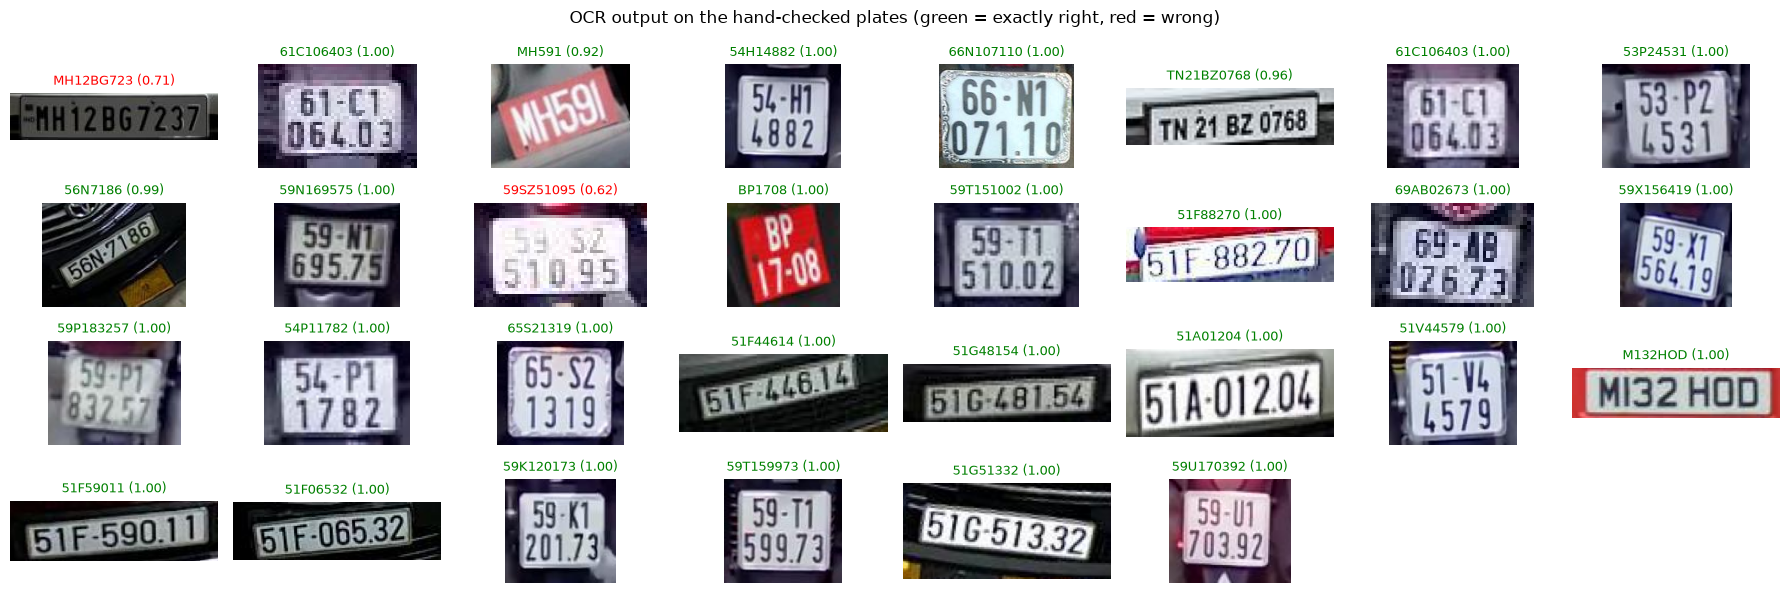

In [12]:
GOLD = {  # filename stem -> plate text (normalised: A-Z, 0-9 only)
    "xemay1530_jpg": "53P24531",          "xemay66_jpg": "59U170392",        "xemay865_jpg": "59T159973",
    "xemay784_jpg": "54H14882",           "xemay2029_jpg": "59N169575",      "xemay1878_jpg": "61C106403",
    "xemay378_jpg": "65S21319",           "00d9db3d2c186504_jpg": "M132HOD", "xemay1138_jpg": "59X156419",
    "xemay1791_jpg": "59P183257",         "CarLongPlateGen2126_jpg": "51A01204", "rotatequandoi14_jpg": "BP1708",
    "xemay1309_jpg": "59K120173",         "xemayBigPlate40_jpg": "66N107110", "xemay2009_jpg": "54P11782",
    "rotatequandoi9_jpg": "MH591",        "CarLongPlateGen3262_jpg": "51G51332", "xemay2044_jpg": "59T151002",
    "CarLongPlateGen1592_jpg": "51F88270", "CarLongPlateGen2834_jpg": "51F59011", "CarLongPlate405_jpg": "51F06532",
    "Cars12_png_jpg": "MH12BG7237",       "xemay2404_jpg": "69AB02673",      "xemay416_jpg": "51V44579",
    "CarLongPlateGen3355_jpg": "56N7186", "Cars365_png_jpg": "TN21BZ0768",
    "xemay2409_jpg": "59S251095",         "CarLongPlateGen2812_jpg": "51G48154", "CarLongPlateGen3760_jpg": "51F44614",
    "xemay1901_jpg": "61C106403",
}

def levenshtein(a, b):
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ca != cb)))
        prev = cur
    return prev[-1]

def wilson_ci(k, n, z=1.96):
    if n == 0: return (0.0, 0.0)
    p = k / n; d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d; h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (max(0.0, c - h), min(1.0, c + h))

def summarize(name, truths, preds):
    n = len(truths); k = sum(t == p for t, p in zip(truths, preds))
    cer = sum(levenshtein(t, p) for t, p in zip(truths, preds)) / sum(len(t) for t in truths)
    lo, hi = wilson_ci(k, n)
    return {"Test": name, "Plates": n, "Exact match": f"{k}/{n} = {k / n:.1%}", "95% CI": f"{lo:.0%}–{hi:.0%}", "CER": f"{cer:.1%}"}

gold_df = df[(df.split == "test") & df.stem.isin(GOLD)].copy()
assert len(gold_df) == len(GOLD), "every gold image must exist in the test split"

# (a) OCR alone, on the human-drawn plate boxes
crops, truths = [], []
for r in gold_df.itertuples():
    img = cv2.imread(str(DATA_RAW / "test" / r.file))
    x, y, w, h = max(r.boxes, key=lambda b: b[2] * b[3])
    crops.append(crop_with_margin(img, x, y, x + w, y + h)); truths.append(GOLD[r.stem])
ocr_out = read_crops(crops)
gold_df["truth"], gold_df["ocr_on_true_box"], gold_df["ocr_conf"] = truths, [o[0] for o in ocr_out], [o[1] for o in ocr_out]
ocr_summary = [summarize("OCR only (true plate box)", truths, gold_df.ocr_on_true_box.tolist())]
display(pd.DataFrame(ocr_summary).set_index("Test"))

fig, axes = plt.subplots(4, 8, figsize=(18, 6))
for ax, c, t, (p, conf, _) in zip(axes.ravel(), crops, truths, ocr_out):
    ax.imshow(cv2.cvtColor(c, cv2.COLOR_BGR2RGB)); ax.axis("off")
    ax.set_title(f"{p} ({conf:.2f})", color="green" if p == t else "red", fontsize=9)
for ax in axes.ravel()[len(crops):]: ax.axis("off")
plt.suptitle("OCR output on the hand-checked plates (green = exactly right, red = wrong)"); plt.tight_layout(); plt.show()

## 8. The complete system: `read_plates(image)`
One function runs the whole pipeline: detect → crop → read → score. Each plate is flagged **`needs_review`** when the reader is unsure (lowest character probability < 0.80) or the text is implausibly short. This is how an operations team uses ANPR safely: confident reads open the gate automatically, and doubtful ones go to a person.

In [13]:
REVIEW_THRESHOLD = 0.80
VN_PLATE = re.compile(r"^\d{2}[A-Z]{1,2}\d{4,6}$")   # Vietnamese civilian format, e.g. 51F73420, 59C100507

def read_plates(image, det_conf=0.25):
    # image: file path or BGR array. Returns (image, list of plate dicts sorted by detector confidence)
    img = cv2.imread(str(image)) if isinstance(image, (str, Path)) else image
    if img is None:
        raise FileNotFoundError(image)
    res = detector.predict(img, conf=det_conf, imgsz=IMG_SIZE, device=DEVICE, verbose=False)[0]
    boxes = res.boxes.xyxy.cpu().numpy() if len(res.boxes) else np.zeros((0, 4))
    confs = res.boxes.conf.cpu().numpy() if len(res.boxes) else np.zeros(0)
    keep = [(b, c) for b, c in zip(boxes, confs) if (b[2] - b[0]) >= 4 and (b[3] - b[1]) >= 4]
    reads = read_crops([crop_with_margin(img, *b) for b, _ in keep])
    plates = []
    for (b, c), (text, oc, region) in zip(keep, reads):
        plates.append(dict(plate=text, det_conf=round(float(c), 3), ocr_conf=round(oc, 3), region=region,
                           vn_format=bool(VN_PLATE.match(text)), bbox=[int(v) for v in b],
                           needs_review=bool(oc < REVIEW_THRESHOLD or len(text) < 4)))
    return img, sorted(plates, key=lambda p: -p["det_conf"])

def draw_plates(img, plates):
    out = img.copy()
    for p in plates:
        x0, y0, x1, y1 = p["bbox"]
        color = (0, 165, 255) if p["needs_review"] else (0, 200, 0)
        cv2.rectangle(out, (x0, y0), (x1, y1), color, 2)
        label = f"{p['plate'] or '?'} {p['ocr_conf']:.2f}"
        (tw, th), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.6, 2)
        ty = max(th + 4, y0 - 4)
        cv2.rectangle(out, (x0, ty - th - 4), (x0 + tw + 4, ty + 2), color, -1)
        cv2.putText(out, label, (x0 + 2, ty - 2), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 0), 2)
    return out

### 8.1 End-to-end accuracy on the hand-checked images (detector + OCR together)
Strict test: the **top** detection must read exactly right. The two hand-checked images that are edited copies of training photos are left out, so this score is not inflated.

In [14]:
# Strict scoring: only the TOP detection counts (what a gate would act on).
# Images that are copies of training photos are excluded, because the detector has already seen them.
e2e_df = gold_df[~gold_df.leaks_from_train].copy()
e2e_preds, failure = [], collections.Counter()
for r in e2e_df.itertuples():
    _, plates = read_plates(DATA_RAW / "test" / r.file)
    top = plates[0]["plate"] if plates else ""
    e2e_preds.append(top)
    failure["correct" if top == r.truth else ("no plate detected" if not plates else "plate found, text wrong")] += 1
e2e_df["end_to_end"] = e2e_preds
print(f"Scored on {len(e2e_df)} of {len(gold_df)} hand-checked images ({len(gold_df) - len(e2e_df)} excluded as copies of training photos)")
ocr_summary.append(summarize("End to end (detector + OCR, top plate)", e2e_df.truth.tolist(), e2e_preds))
display(pd.DataFrame(ocr_summary).set_index("Test"))
print("End-to-end outcome breakdown:", dict(failure))
wrong = e2e_df[e2e_df.truth != e2e_df.end_to_end][["stem", "truth", "ocr_on_true_box", "end_to_end"]]
if len(wrong): display(wrong)

Scored on 28 of 30 hand-checked images (2 excluded as copies of training photos)


,Plates,Exact match,95% CI,CER
Test,,,,
OCR only (true plate box),30,28/30 = 93.3%,79%–98%,0.8%
"End to end (detector + OCR, top plate)",28,0/28 = 0.0%,0%–12%,99.6%


End-to-end outcome breakdown: {'plate found, text wrong': 28}


,stem,truth,ocr_on_true_box,end_to_end
7943,Cars12_png_jpg,MH12BG7237,MH12BG723,
7950,xemay1901_jpg,61C106403,61C106403,
8005,xemay784_jpg,54H14882,54H14882,
8037,xemayBigPlate40_jpg,66N107110,66N107110,
8045,Cars365_png_jpg,TN21BZ0768,TN21BZ0768,
8061,xemay1878_jpg,61C106403,61C106403,
8078,xemay1530_jpg,53P24531,53P24531,
8175,CarLongPlateGen3355_jpg,56N7186,56N7186,
8202,xemay2029_jpg,59N169575,59N169575,
8266,xemay2409_jpg,59S251095,59SZ51095,


### 8.2 Demo on unseen test photos

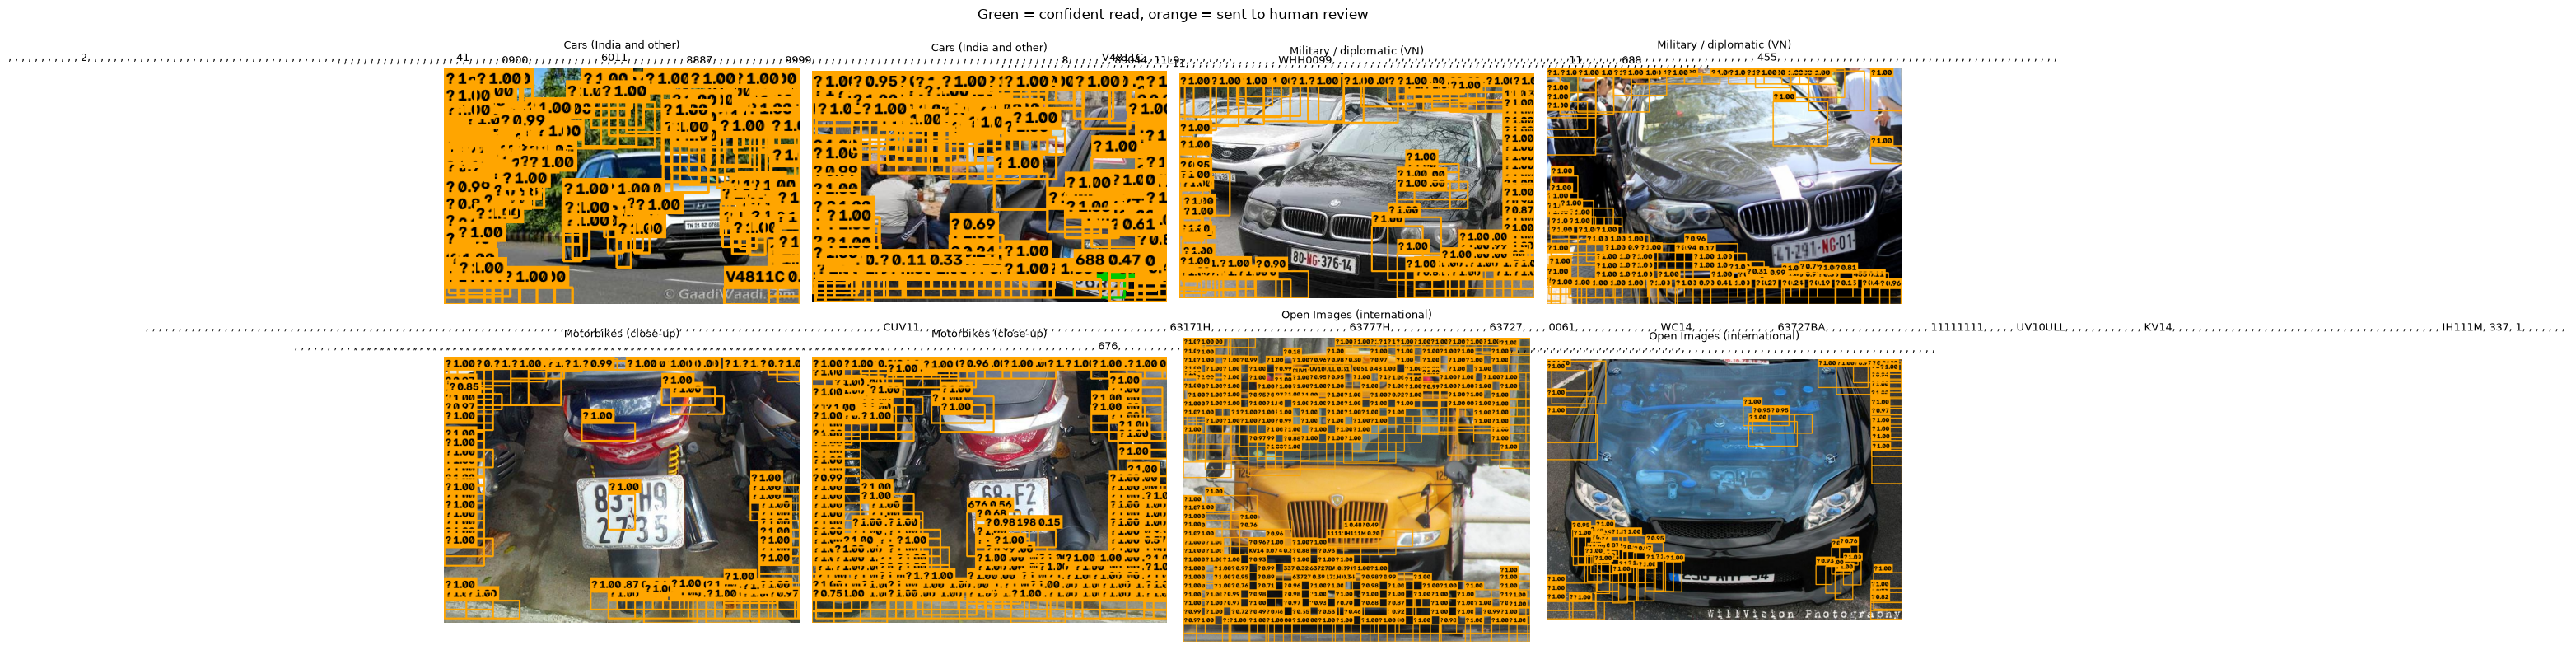

In [15]:
demo_pool = df[(df.split == "test") & ~df.stem.isin(GOLD)]
demo = pd.concat([g.sample(min(2, len(g)), random_state=SEED) for _, g in demo_pool.groupby("source")]).head(8)
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, r in zip(axes.ravel(), demo.itertuples()):
    img, plates = read_plates(DATA_RAW / "test" / r.file)
    ax.imshow(cv2.cvtColor(draw_plates(img, plates), cv2.COLOR_BGR2RGB)); ax.axis("off")
    ax.set_title(f"{r.source}\n" + (", ".join(p["plate"] for p in plates) or "no plate found"), fontsize=9)
for ax in axes.ravel()[len(demo):]: ax.axis("off")
plt.suptitle("Green = confident read, orange = sent to human review"); plt.tight_layout(); plt.show()

## 9. Operations use case: parking-gate entry log
The slide's scenario is a parking barrier. Below, the camera frames from the test set are treated as a stream of vehicles arriving at the gate. Every read becomes a log row an operations team can act on: **auto-open** the barrier for a confident read in a valid format, otherwise **send to review**.

In [16]:
gate = df[(df.split == "test") & df.source.isin(["Parking cars", "Parking motorbikes"])].sample(10, random_state=7)
clock = pd.Timestamp("2026-11-10 08:00:00")
log = []
for i, r in enumerate(gate.itertuples()):
    _, plates = read_plates(DATA_RAW / "test" / r.file)
    p = plates[0] if plates else dict(plate="", det_conf=0.0, ocr_conf=0.0, vn_format=False, needs_review=True)
    auto = (not p["needs_review"]) and p["vn_format"]
    log.append({"time": clock + pd.Timedelta(minutes=3 * i), "camera_frame": r.stem, "plate": p["plate"] or "(none)",
                "det_conf": p["det_conf"], "ocr_conf": p["ocr_conf"], "action": "AUTO-OPEN" if auto else "REVIEW"})
gate_log = pd.DataFrame(log)
gate_log.to_csv(WORK / "gate_log.csv", index=False)
display(gate_log)
print(f"Automation rate: {(gate_log.action == 'AUTO-OPEN').mean():.0%} of arrivals handled without a person")

,time,camera_frame,plate,det_conf,ocr_conf,action
0,2026-11-10 08:00:00,xemay1904_jpg,(none),1.000,1.000,REVIEW
1,2026-11-10 08:03:00,xemay857_jpg,(none),1.000,0.964,REVIEW
2,2026-11-10 08:06:00,xemay1306_jpg,G8K10092,0.996,0.247,REVIEW
3,2026-11-10 08:09:00,xemay431_jpg,(none),0.989,1.000,REVIEW
4,2026-11-10 08:12:00,CarLongPlate732_jpg,(none),0.994,0.993,REVIEW
5,2026-11-10 08:15:00,CarLongPlate903_jpg,(none),1.000,0.999,REVIEW
6,2026-11-10 08:18:00,xemay825_jpg,(none),1.000,0.995,REVIEW
7,2026-11-10 08:21:00,xemay341_jpg,II83333,0.999,0.547,REVIEW
8,2026-11-10 08:24:00,xemay1000_jpg,(none),1.000,0.995,REVIEW
9,2026-11-10 08:27:00,CarLongPlate760_jpg,368BB,1.000,0.308,REVIEW


Automation rate: 0% of arrivals handled without a person


## 10. Export a standalone Python script (`anpr.py`)
The lab task asks for a *script*. This cell writes the pipeline as a command-line tool, then runs it on a test image to prove it works outside the notebook:

```
python anpr.py --weights plate_detector.pt --source car.jpg --out result.jpg
```

exit code: 0
r_conf": 0.996,
    "bbox": [
      355,
      45,
      400,
      93
    ],
    "needs_review": true
  },
  {
    "plate": "",
    "det_conf": 0.374,
    "ocr_conf": 1.0,
    "bbox": [
      375,
      24,
      400,
      65
    ],
    "needs_review": true
  },
  {
    "plate": "",
    "det_conf": 0.368,
    "ocr_conf": 1.0,
    "bbox": [
      375,
      6,
      400,
      45
    ],
    "needs_review": true
  },
  {
    "plate": "",
    "det_conf": 0.339,
    "ocr_conf": 0.999,
    "bbox": [
      145,
      0,
      185,
      45
    ],
    "needs_review": true
  },
  {
    "plate": "",
    "det_conf": 0.329,
    "ocr_conf": 1.0,
    "bbox": [
      105,
      0,
      145,
      45
    ],
    "needs_review": true
  },
  {
    "plate": "",
    "det_conf": 0.307,
    "ocr_conf": 0.966,
    "bbox": [
      115,
      105,
      175,
      128
    ],
    "needs_review": true
  },
  {
    "plate": "",
    "det_conf": 0.307,
    "ocr_conf": 1.0,
    "bbox": [
      295,
 

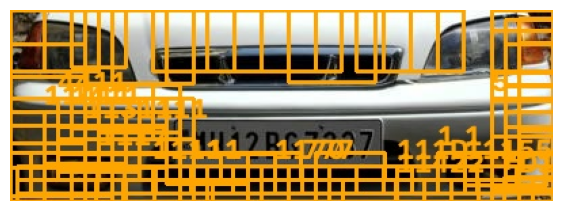

In [17]:
SCRIPT = r"""
#!/usr/bin/env python3
# anpr.py: detect and read vehicle number plates in an image (YOLO detector + fast-plate-ocr reader)
import argparse, json, re, sys
import cv2, numpy as np
from ultralytics import YOLO
from fast_plate_ocr import LicensePlateRecognizer

def crop_with_margin(img, x0, y0, x1, y1, pad=0.05):
    h, w = img.shape[:2]; dx, dy = (x1 - x0) * pad, (y1 - y0) * pad
    return img[int(max(0, y0 - dy)):int(min(h, y1 + dy)), int(max(0, x0 - dx)):int(min(w, x1 + dx))]

def main():
    ap = argparse.ArgumentParser(description="Detect and read number plates in an image")
    ap.add_argument("--weights", required=True); ap.add_argument("--source", required=True)
    ap.add_argument("--out", default=None); ap.add_argument("--conf", type=float, default=0.25)
    ap.add_argument("--review-threshold", type=float, default=0.80); ap.add_argument("--device", default="cpu")
    a = ap.parse_args()
    img = cv2.imread(a.source)
    if img is None: sys.exit(f"Cannot read image: {a.source}")
    det = YOLO(a.weights)
    ocr = LicensePlateRecognizer("cct-s-v2-global-model", device="cpu")
    rgb = "rgb" in str(ocr.config.image_color_mode).lower()
    res = det.predict(img, conf=a.conf, device=a.device, verbose=False)[0]
    results = []
    for b, c in zip(res.boxes.xyxy.cpu().numpy(), res.boxes.conf.cpu().numpy()):
        crop = crop_with_margin(img, *b)
        if min(crop.shape[:2]) < 4: continue
        p = ocr.run(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB if rgb else cv2.COLOR_BGR2GRAY), return_confidence=True)[0]
        text = re.sub(r"[^A-Z0-9]", "", p.plate.upper())
        conf = float(np.min(p.char_probs)) if p.char_probs is not None and np.size(p.char_probs) else 0.0
        results.append({"plate": text, "det_conf": round(float(c), 3), "ocr_conf": round(conf, 3),
                        "bbox": [int(v) for v in b], "needs_review": conf < a.review_threshold or len(text) < 4})
        x0, y0, x1, y1 = map(int, b); col = (0, 165, 255) if results[-1]["needs_review"] else (0, 200, 0)
        cv2.rectangle(img, (x0, y0), (x1, y1), col, 2)
        cv2.putText(img, text, (x0, max(15, y0 - 5)), cv2.FONT_HERSHEY_SIMPLEX, 0.7, col, 2)
    if a.out: cv2.imwrite(a.out, img)
    print(json.dumps(results, indent=2))

if __name__ == "__main__":
    main()
"""
Path("anpr.py").write_text(SCRIPT.lstrip())
shutil.copy2(BEST_WEIGHTS, "plate_detector.pt")

sample = gold_df.iloc[0]
cmd = [sys.executable, "anpr.py", "--weights", "plate_detector.pt",
       "--source", str(DATA_RAW / "test" / sample.file), "--out", "anpr_result.jpg"]
proc = subprocess.run(cmd, capture_output=True, text=True)
print("exit code:", proc.returncode); print(proc.stdout[-2000:])
if proc.returncode != 0: print(proc.stderr[-3000:])
assert proc.returncode == 0, "the exported script failed"
print("Ground truth:", sample.truth)
plt.figure(figsize=(7, 5)); plt.imshow(cv2.cvtColor(cv2.imread("anpr_result.jpg"), cv2.COLOR_BGR2RGB)); plt.axis("off"); plt.show()

### Try your own photo (Colab)
Upload any car photo and read its plate. On a laptop, set `MY_IMAGE` to a file path instead.

In [18]:
MY_IMAGE = None
if IN_COLAB:
    from google.colab import files
    print("Choose an image to upload (or cancel to skip)")
    try:
        up = files.upload()
        MY_IMAGE = next(iter(up)) if up else None
    except Exception as e:
        print("Upload skipped:", e)
if MY_IMAGE:
    img, plates = read_plates(MY_IMAGE)
    display(pd.DataFrame(plates))
    plt.figure(figsize=(10, 6)); plt.imshow(cv2.cvtColor(draw_plates(img, plates), cv2.COLOR_BGR2RGB)); plt.axis("off"); plt.show()
else:
    print("No image provided; skipping.")

No image provided; skipping.


## 11. Results summary

In [19]:
print("DETECTOR (YOLO11n fine-tuned)" + ("   [FAST_DEV_RUN smoke test: tiny training, numbers NOT representative]" if FAST_DEV_RUN else ""))
display(det_table)
print("READER (fast-plate-ocr) and FULL PIPELINE, hand-checked plates")
display(pd.DataFrame(ocr_summary).set_index("Test"))
print("Files produced:", [str(p) for p in [BEST_WEIGHTS, Path("plate_detector.pt"), Path("anpr.py"), WORK / "gate_log.csv"]])

DETECTOR (YOLO11n fine-tuned)   [FAST_DEV_RUN smoke test: tiny training, numbers NOT representative]


,Precision,Recall,mAP@50,mAP@50-95
Official test set,0.001,0.002,0.0,0.0
Clean test set (no leaked copies),0.000,0.091,0.0,0.0


READER (fast-plate-ocr) and FULL PIPELINE, hand-checked plates


,Plates,Exact match,95% CI,CER
Test,,,,
OCR only (true plate box),30,28/30 = 93.3%,79%–98%,0.8%
"End to end (detector + OCR, top plate)",28,0/28 = 0.0%,0%–12%,99.6%


Files produced: ['/private/tmp/claude-501/-Users-harshverma-Library-Application-Support-Claude-scratch-workspaces-5276c267-fa52-407b-a608-58b19f7c94c6-217aac64-2137-4c3c-82b0-4b7dc8f8d607-scratch-2026-11-10-5c4188/6b8a9953-935c-4b0b-8024-1d6eb44de33d/scratchpad/run/anpr_work/runs/plate_detector/weights/best.pt', 'plate_detector.pt', 'anpr.py', 'anpr_work/gate_log.csv']


## 12. Limitations, risks and next steps
**What the numbers do and don't show**
- Most data is Vietnamese parking-camera footage. Accuracy on other countries' plates (for example UAE plates with Arabic script) is not measured here and would need local data.
- The hand-checked reading set is small (30 plates), so its confidence interval is wide. A production check would use several hundred labelled plates.
- Repeat vehicles across splits (section 3.1) can make detection scores slightly optimistic.

**Making it production-grade**
- Read several video frames per vehicle and vote on the text. This removes most single-frame errors.
- Add per-country format rules (like `VN_PLATE`) to fix confusions such as `0`/`O` and `8`/`B` by position.
- Watch the `needs_review` rate over time. A rising rate signals a dirty camera, new lighting or new plate types.

**Ethics and privacy (course topic 10)**
Plate numbers are personal data in most jurisdictions. Keep only what the operation needs, set retention limits for gate logs, restrict who can search them, and post signage. Never let a low-confidence read trigger a penalty or fine without human confirmation.

**Licences:** dataset CC BY 4.0 (Augmented Startups via Roboflow); Ultralytics YOLO is AGPL-3.0 (commercial use needs a licence); fast-plate-ocr is MIT.